# LangGraph — drawing the loop yourself

**Week 13 · Session 1**

All of last week, `create_agent` was quietly a **graph**: a `model` node, a `tools` node,
and an edge that loops between them until the model stops asking for tools. You never saw
it, and you couldn't change it.

**LangGraph** is the library that graph is built with. You draw your own:

- **State** — a typed dict that flows through the graph (last week: the `messages` list).
- **Nodes** — plain Python functions that read state and return updates.
- **Edges** — fixed arrows, or **conditional** ones where your code (or a model) picks the next node.
- **Checkpoints** — state saved after every step, so you can resume, pause for a human, or rewind.

| Week 10 | Week 11 · Agents SDK | Week 12 · LangChain | Week 13 · LangGraph |
|---|---|---|---|
| the `while` loop | `Runner` | `create_agent` | **you draw the loop** |
| `if` statements | handoffs | middleware | **conditional edges** |
| `messages` list | `Session` | checkpointer | **state + checkpointer** |
| — | `RunState` | `Command(resume=…)` | **time travel** |

**Today's project:** a support-ticket router for Nimbus, the company from last week. Every
ticket must pass a safety check, and every reply must pass a review before it's sent. That
order is **policy**, not something a model should decide — which is exactly when you draw
the graph yourself.

In [1]:
%pip install -q "langchain==1.4.2" "langchain-openai==1.6.2" "langgraph==1.2.11" python-dotenv pandas

In [2]:
import os, json, re, operator, getpass
from pathlib import Path
from typing import Annotated, Literal, TypedDict, Optional

try:
    from dotenv import load_dotenv, find_dotenv
    load_dotenv(find_dotenv(usecwd=True) or Path.cwd().parent / ".env")
except ImportError:
    pass
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key: ")

# Anaconda 'base' fix (same as Week 11). httpx2 2.12+ decompresses brotli with output_buffer_limit=... as a keyword.
# Anaconda's brotli 1.x exposes process() as a C function that rejects kwargs
# ("TypeError: process() takes no keyword arguments"). Wrap it so OpenAI
# Responses (which often arrive Content-Encoding: br) can be decoded.
try:
    import brotli as _brotli
    from httpx2._decoders import BrotliDecoder as _BrotliDecoder
    _probe = _brotli.Decompressor()
    try:
        _probe.process(b"", output_buffer_limit=1)
    except TypeError:
        _brotli_init = _BrotliDecoder.__init__
        def _brotli_init_compat(self, *args, **kwargs):
            _brotli_init(self, *args, **kwargs)
            _impl = self._decompress
            self._decompress = lambda data, output_buffer_limit=None, **_k: _impl(data)
        _BrotliDecoder.__init__ = _brotli_init_compat
except Exception:
    pass

import pandas as pd
from pydantic import BaseModel, Field
from IPython.display import Image, Markdown, display
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain.chat_models import init_chat_model

MODEL = "openai:gpt-4.1-mini"
llm = init_chat_model(MODEL, temperature=0)


def draw(graph):
    """Show a compiled graph as a picture (needs internet), or as Mermaid text without it."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


print("ready")

ready


---
# Part 1 — The smallest graph

A node is a function that takes the state and returns **only the keys it wants to
change**. LangGraph merges that update into the state and moves along an edge.

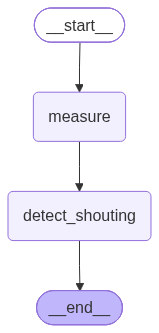

{'text': 'MY WATCH IS BURNING HOT', 'word_count': 5, 'shouting': True}


In [3]:
class TicketState(TypedDict):
    text: str
    word_count: int
    shouting: bool


def measure(state: TicketState) -> dict:
    return {"word_count": len(state["text"].split())}


def detect_shouting(state: TicketState) -> dict:
    letters = [c for c in state["text"] if c.isalpha()]
    return {"shouting": sum(c.isupper() for c in letters) > 0.6 * len(letters)}


builder = StateGraph(TicketState)
builder.add_node("measure", measure)
builder.add_node("detect_shouting", detect_shouting)
builder.add_edge(START, "measure")
builder.add_edge("measure", "detect_shouting")
builder.add_edge("detect_shouting", END)

graph = builder.compile()
draw(graph)
print(graph.invoke({"text": "MY WATCH IS BURNING HOT"}))

Three things to notice:

1. **Build, then compile.** `StateGraph` is a blueprint; `compile()` checks it (no dangling
   nodes, no unreachable ends) and gives you something you can `invoke`, `stream` or `batch`.
   It's a Runnable, like everything last week.
2. **Nodes return updates, not the whole state.** `measure` never mentions `shouting`.
3. **No LLM anywhere.** A graph is just control flow. Models are one kind of node.

---
# Part 2 — Reducers: how updates merge

By default an update **overwrites** the key. Sometimes you want to **add** to it instead —
a log, a list of messages, a list of search results. That's what a **reducer** is for.

In [4]:
class NoReducer(TypedDict):
    log: list[str]


class WithReducer(TypedDict):
    log: Annotated[list[str], operator.add]     # updates are APPENDED, not overwritten


def step_a(state): return {"log": ["a ran"]}
def step_b(state): return {"log": ["b ran"]}


for schema in (NoReducer, WithReducer):
    b = StateGraph(schema)
    b.add_node("a", step_a); b.add_node("b", step_b)
    b.add_edge(START, "a"); b.add_edge("a", "b"); b.add_edge("b", END)
    print(f"{schema.__name__:<12} ->", b.compile().invoke({"log": ["start"]})["log"])

NoReducer    -> ['b ran']
WithReducer  -> ['start', 'a ran', 'b ran']


Without the reducer, `b` silently **replaced** everything `a` wrote. That's one of the most
common LangGraph bugs: a list that "loses" items is almost always a missing reducer.

`MessagesState` — which you'll use for agents — is just a state with one key, `messages`,
whose reducer (`add_messages`) appends new messages and updates existing ones by id.

---
# Part 3 — Conditional edges and loops

A conditional edge calls a **routing function** that returns the name of the next node.
Point an edge backwards and you have a loop. This is Week 10's `while` loop and Week 10's
router, both as edges.

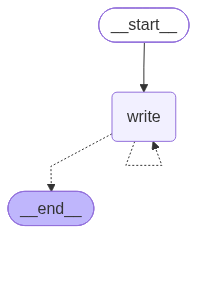

attempt 1: 14 words
attempt 2: 9 words
final: Sorry for the delay; your delivery will arrive shortly.


In [5]:
class DraftState(TypedDict):
    draft: str
    attempts: int
    history: Annotated[list[str], operator.add]


def write(state: DraftState) -> dict:
    n = state["attempts"] + 1
    text = llm.invoke(f"Write a one-sentence apology for a late delivery. Attempt {n}; "
                      f"previous attempts were rejected for being too long. Keep it under {30 - 8 * n} words.").content
    return {"draft": text, "attempts": n, "history": [f"attempt {n}: {len(text.split())} words"]}


def good_enough(state: DraftState) -> Literal["write", "__end__"]:
    if len(state["draft"].split()) <= 12:
        return END                       # short enough: done
    if state["attempts"] >= 3:
        return END                       # budget spent: stop anyway
    return "write"                       # loop back


b = StateGraph(DraftState)
b.add_node("write", write)
b.add_edge(START, "write")
b.add_conditional_edges("write", good_enough)
loop = b.compile()
draw(loop)

out = loop.invoke({"draft": "", "attempts": 0, "history": []})
print("\n".join(out["history"]))
print("final:", out["draft"])

The routing function checks **two** exits: the goal ("short enough") and the budget ("three
attempts"). Every loop you draw needs both — Week 10's `max_steps`, drawn as an edge.

LangGraph also has a global safety net: `recursion_limit` (default 25 steps). Exceed it and
the run stops with `GraphRecursionError` rather than looping forever.

---
# Part 4 — `create_agent`, opened up

Here's last week's agent, built by hand. Two nodes, one conditional edge, one back-edge.

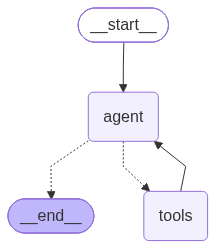

 human: How much for an Orbit and two Echo Bars?
    ai: ['get_price', 'get_price']
  tool: Orbit: INR 3999
  tool: Echo Bar: INR 1799
    ai: The price for an Orbit is INR 3999 and for one Echo Bar is INR 1799. 

For two Echo Bars, the cost w


In [6]:
from langchain.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition

PRICES = {"pulse x1": 2499, "orbit": 3999, "echo bar": 1799}


@tool
def get_price(product: str) -> str:
    """Current price in INR of a Nimbus product: "Pulse X1", "Orbit" or "Echo Bar"."""
    for name, price in PRICES.items():
        if name in product.lower():
            return f"{name.title()}: INR {price}"
    return "Unknown product."


tools = [get_price]
model_with_tools = llm.bind_tools(tools)


def agent(state: MessagesState) -> dict:
    return {"messages": [model_with_tools.invoke(state["messages"])]}


b = StateGraph(MessagesState)
b.add_node("agent", agent)
b.add_node("tools", ToolNode(tools))           # runs whatever tool calls the last message asked for
b.add_edge(START, "agent")
b.add_conditional_edges("agent", tools_condition)   # tool calls? -> "tools", otherwise -> END
b.add_edge("tools", "agent")                   # the loop
react = b.compile()
draw(react)

r = react.invoke({"messages": [{"role": "user", "content": "How much for an Orbit and two Echo Bars?"}]})
for m in r["messages"]:
    calls = [tc["name"] for tc in getattr(m, "tool_calls", None) or []]
    print(f"{m.type:>6}: {calls or m.content[:100]}")

That's **the whole of `create_agent`**: `agent → tools → agent → … → END`. Put the picture
next to Week 10's `while` loop — it's the same thing, drawn instead of written.

`tools_condition` is a routing function: it returns `"tools"` if the last message has tool
calls, and `END` otherwise. You could write it yourself in three lines.

**Why draw it by hand?** Because now you can change it: add a node that checks every tool
result, a second model for review, a human pause before tools run. You'll do all three this
week.


## 4.1 Two ways LangChain agents and LangGraph fit together

We just *claimed* the hand-built graph is what `create_agent` does. Don't take it on trust —
`create_agent` hands you a LangGraph object, so you can ask it to draw itself.

In [ ]:
from langchain.agents import create_agent

prebuilt = create_agent(llm, tools=tools)          # last week's one-liner

print("create_agent returns:", type(prebuilt).__name__)      # ...a LangGraph graph
print()
print(prebuilt.get_graph().draw_mermaid())

create_agent returns: CompiledStateGraph

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools -.-> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



Same shape as the one we built by hand — `__start__ → model`, `model ⇢ tools`,
`model ⇢ __end__`, `tools ⇢ model`. The only difference is the node's name: LangChain calls it
`model`, we called it `agent`.

**The second direction is the useful one:** a whole LangChain agent can be *one node* in a
graph you own. The agent keeps its freedom inside that node — it still decides which tools to
call — while your edges decide what happens before and after it.

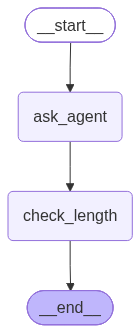

The price for an Orbit is INR 3999. The price for one Echo Bar is INR 1799. 

For two Echo Bars, the cost would be 2 x 1799 = INR 3598.

So, the total cost for one Orbit and two Echo Bars would be 3999 + 3598 = INR 7597.

words: 50


In [ ]:
# A whole LangChain agent, used as ONE node inside a graph you own.
price_agent = create_agent(llm, tools=tools,
                           system_prompt="Answer Nimbus pricing questions using the tool.")


class Enquiry(TypedDict):
    question: str
    answer: str
    words: int


def ask_agent(s: Enquiry) -> dict:         # the node just calls the agent and keeps its reply
    out = price_agent.invoke({"messages": [{"role": "user", "content": s["question"]}]})
    return {"answer": out["messages"][-1].content}


def check_length(s: Enquiry) -> dict:      # a plain code node, right after it
    return {"words": len(s["answer"].split())}


b = StateGraph(Enquiry)
b.add_node("ask_agent", ask_agent)
b.add_node("check_length", check_length)
b.add_edge(START, "ask_agent")
b.add_edge("ask_agent", "check_length")
b.add_edge("check_length", END)
enquiry = b.compile()
draw(enquiry)

out = enquiry.invoke({"question": "How much for an Orbit and two Echo Bars?"})
print(out["answer"])
print("\nwords:", out["words"])

Notice what each side owns. The **agent node** worked out that two Echo Bars means
2 × 1799 — open-ended reasoning, exactly what an agent is for. The **graph** guaranteed that
`check_length` runs afterwards, every time, no matter what the agent decided to do.

That is the pattern you'll use most in production:

> **a graph on the outside for the steps that must happen, an agent inside one node for the
> part where you genuinely want the model to choose.**

Keep it in mind for Part 7 — the ticket router could have used an agent for `draft_reply`
instead of a plain model call, and the policy would still have been safe.

---
# Part 5 — Checkpoints and time travel

Compile with a checkpointer and LangGraph saves the state **after every step**, keyed by a
`thread_id`. Last week that gave you memory. It also gives you history — and the ability to
**rewind and branch**.

In [7]:
saved = b.compile(checkpointer=InMemorySaver())
thread = {"configurable": {"thread_id": "priya"}}

saved.invoke({"messages": [{"role": "user", "content": "Price of the Pulse X1?"}]}, thread)
saved.invoke({"messages": [{"role": "user", "content": "And the Orbit?"}]}, thread)

history = list(saved.get_state_history(thread))
print(f"{len(history)} checkpoints saved for this thread (newest first):\n")
for snap in history:
    last = snap.values["messages"][-1] if snap.values.get("messages") else None
    what = (last.type + ": " + (str(last.content)[:50] or str([t['name'] for t in last.tool_calls]))) if last else "(empty)"
    print(f"  step {snap.metadata.get('step'):>2}  next={str(snap.next):<12} {what}")

10 checkpoints saved for this thread (newest first):

  step  8  next=()           ai: The price of the Orbit is INR 3999.
  step  7  next=('agent',)   tool: Orbit: INR 3999
  step  6  next=('tools',)   ai: ['get_price']
  step  5  next=('agent',)   human: And the Orbit?
  step  4  next=('__start__',) ai: The price of the Pulse X1 is INR 2499.
  step  3  next=()           ai: The price of the Pulse X1 is INR 2499.
  step  2  next=('agent',)   tool: Pulse X1: INR 2499
  step  1  next=('tools',)   ai: ['get_price']
  step  0  next=('agent',)   human: Price of the Pulse X1?
  step -1  next=('__start__',) (empty)


Every step of both turns is a checkpoint you can go back to. **Time travel** means picking
one, optionally changing the state there, and running forward from it. The original history
stays; you get a new branch.

In [8]:
# Rewind to the moment just BEFORE the agent answered the second question...
second_q = next(snap for snap in history
                if snap.next == ("agent",) and snap.values["messages"][-1].type == "human"
                and "Orbit" in snap.values["messages"][-1].content)
old = second_q.values["messages"][-1]
print("rewinding to step", second_q.metadata.get("step"), "- the question was:", repr(old.content))

# ...and replace that question. Same message id = add_messages REPLACES it instead of appending.
from langchain.messages import HumanMessage
fork = saved.update_state(second_q.config, {"messages": [HumanMessage("What about the Echo Bar instead?", id=old.id)]})
branch = saved.invoke(None, fork)                # None = "just continue from here"

print("\nbranch answer  :", branch["messages"][-1].content)
print("original answer:", history[0].values["messages"][-1].content, "  (still in the history)")

rewinding to step 5 - the question was: 'And the Orbit?'



branch answer  : The price of the Echo Bar is INR 1799.
original answer: The price of the Orbit is INR 3999.   (still in the history)


Two answers now exist side by side: the original conversation ("the Orbit") and a branch
from the same point ("the Echo Bar"). After a fork, the thread's *latest* checkpoint is the
branch; the original lives on in the history. That's how you **debug** an agent — rewind to the step
where it went wrong, change one thing, rerun only what follows — and how you'd build "undo"
or "try another answer" into a product.

---
# Part 6 — Three ways to stream

| `stream_mode` | You get | Use it for |
|---|---|---|
| `"updates"` | what each node changed | progress UIs, logging |
| `"values"` | the full state after each step | debugging |
| `"messages"` | LLM tokens as they're generated | chat typing effect |

In [9]:
q = {"messages": [{"role": "user", "content": "Price of the Orbit?"}]}
print("updates :", [list(chunk) for chunk in react.stream(q, stream_mode="updates")])
print("values  :", [len(s["messages"]) for s in react.stream(q, stream_mode="values")], "messages after each step")
print("messages: ", end="")
for token, meta in react.stream(q, stream_mode="messages"):
    if meta["langgraph_node"] == "agent" and token.content:
        print(token.content, end="", flush=True)
print()

updates : [['agent'], ['tools'], ['agent']]


values  : [1, 2, 3, 4] messages after each step
messages: 

The

 price

 of

...

 is

 INR

399

9

.

---
# Part 7 — Project: the Nimbus support-ticket router

**The job.** Tickets arrive. Each must be classified, checked for safety, scored for urgency,
and either escalated or answered from the knowledge base — and **no reply goes out until a
reviewer passes it**.

**Why a graph, not `create_agent`?** Because the order is policy. A safety complaint must
*always* reach the safety team; a reply must *always* be reviewed. With an agent you'd be
asking the model to remember that. With a graph, there is no path that skips it.

(Remember Week 11's first guardrail trap: guardrails only ran on the first agent of a turn.
In a graph, the check is a node on every path, so there's nothing to skip.)

## The knowledge base

Nimbus's policies and release notes, from last week.

In [10]:
from langchain_openai import OpenAIEmbeddings
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_core.documents import Document

KB = {
    "returns-policy": "Returns within 7 days of delivery for a full refund. Defective products are replaced within "
                      "10 working days. Nimbus arranges FREE courier pickup; never ask customers to pay shipping.",
    "warranty-policy": "12-month warranty covering manufacturing defects. Liquid damage beyond the IP rating is not covered.",
    "shipping-policy": "Metros 1-3 days, tier-2 cities 3-5 days, north-east India (e.g. Guwahati) 7-10 days.",
    "support-sla": "Email replies within 48 hours. Safety complaints must reach the product-safety team within 4 hours.",
    "orbit-fw-2.3.1": "Orbit firmware 2.3.1 (10 Apr 2026) fixes overheating during smart charging, the app logout bug "
                      "and workout sync. It installs automatically; users can also update from the app: Settings > Firmware.",
    "pulse-x1-manual": "To re-pair Pulse X1: put both buds in the case, hold the case button 10 seconds, then pair again. "
                       "Firmware 1.5 fixes the left bud disconnecting during calls.",
    "echo-bar-manual": "Echo Bar is IPX5: splashes and rain, NOT submersion. Bluetooth range up to 10 m; walls reduce it.",
    "billing-faq": "Refunds go back to the original payment method within 5-7 working days after pickup. "
                   "Duplicate charges are refunded automatically once confirmed by the payments team.",
}
kb = InMemoryVectorStore.from_documents(
    [Document(page_content=t, metadata={"doc_id": d}) for d, t in KB.items()],
    OpenAIEmbeddings(model="text-embedding-3-small"))
print(len(KB), "KB articles indexed")

8 KB articles indexed


## The state

Everything the router knows about one ticket, as it moves through the graph.

In [11]:
class Ticket(TypedDict, total=False):
    ticket_id: str
    text: str
    customer_tier: Literal["standard", "premium"]
    # filled in by nodes:
    intent: str
    product: str
    safety_flag: bool
    urgency: int
    urgency_reason: str
    kb_context: str
    draft: str
    review_feedback: str
    attempts: int
    outcome: str
    path: Annotated[list[str], operator.add]     # every node appends its name: the ticket's journey

## The nodes

Two use structured output (classify, urgency), one searches the knowledge base, one drafts,
one reviews — an LLM judge, Week 10 style. The safety check is **code**, not a model: a
keyword rule plus the classifier's flag, so it can't be talked out of firing.

In [12]:
class Classification(BaseModel):
    intent: Literal["billing", "technical", "safety", "shipping", "returns", "account", "other"]
    product: Literal["Pulse X1", "Orbit", "Echo Bar", "unknown"]
    mentions_safety: bool = Field(description="Heat, burning, smoke, fire, sparks, swelling battery, injury")


class Urgency(BaseModel):
    urgency: int = Field(ge=1, le=5, description="5 = safety or product unusable; 1 = general question")
    reason: str


class Review(BaseModel):
    approved: bool
    feedback: str = Field(description="If not approved, exactly what to fix")


SAFETY_WORDS = re.compile(r"\b(hot|overheat\w*|burn\w*|smoke|smoking|fire|spark\w*|swell\w*|melt\w*)\b", re.I)


def classify(t: Ticket) -> dict:
    c = llm.with_structured_output(Classification).invoke(
        f"Classify this Nimbus customer support ticket.\n\nTicket: {t['text']}")
    safety = c.mentions_safety or bool(SAFETY_WORDS.search(t["text"]))   # rule OR model: either can flag
    return {"intent": "safety" if safety else c.intent, "product": c.product,
            "safety_flag": safety, "path": ["classify"]}


def assess_urgency(t: Ticket) -> dict:
    if t["safety_flag"]:
        return {"urgency": 5, "urgency_reason": "safety issue (policy: always 5)", "path": ["assess_urgency"]}
    u = llm.with_structured_output(Urgency).invoke(
        f"Customer tier: {t.get('customer_tier', 'standard')}. Intent: {t['intent']}.\n"
        f"Score the urgency of this ticket.\n\nTicket: {t['text']}")
    return {"urgency": u.urgency, "urgency_reason": u.reason, "path": ["assess_urgency"]}


def search_kb(t: Ticket) -> dict:
    hits = kb.similarity_search(f"{t.get('product', '')} {t['text']}", k=3)
    return {"kb_context": "\n".join(f"[{h.metadata['doc_id']}] {h.page_content}" for h in hits),
            "path": ["search_kb"]}


def draft_reply(t: Ticket) -> dict:
    feedback = f"\nA reviewer rejected your last draft. Fix this: {t['review_feedback']}" if t.get("review_feedback") else ""
    text = llm.invoke(
        "Write a short, warm support reply (max 90 words) to this Nimbus customer. Use ONLY the knowledge base; "
        "cite nothing, but never promise anything the KB doesn't say. Sign off as 'Nimbus Support'."
        f"{feedback}\n\nKnowledge base:\n{t['kb_context']}\n\nTicket: {t['text']}").content
    return {"draft": text, "attempts": t.get("attempts", 0) + 1, "path": ["draft_reply"]}


def review_reply(t: Ticket) -> dict:
    r = llm.with_structured_output(Review).invoke(
        "You review support replies before they are sent. Approve ONLY if the reply (1) answers the actual question, "
        "(2) contains nothing the knowledge base doesn't support, (3) promises no timelines or refunds beyond policy, "
        "and (4) is polite and under 90 words.\n\n"
        f"Knowledge base:\n{t['kb_context']}\n\nTicket: {t['text']}\n\nReply:\n{t['draft']}")
    return {"review_feedback": "" if r.approved else r.feedback,
            "outcome": "approved" if r.approved else "", "path": ["review_reply"]}


def escalate_safety(t: Ticket) -> dict:
    return {"outcome": "ESCALATED to product safety (4-hour SLA)", "path": ["escalate_safety"]}


def escalate_human(t: Ticket) -> dict:
    return {"outcome": f"ESCALATED to a human agent (urgency {t.get('urgency')})", "path": ["escalate_human"]}


def send_reply(t: Ticket) -> dict:
    return {"outcome": "REPLY SENT", "path": ["send_reply"]}

## The routing — this is the policy

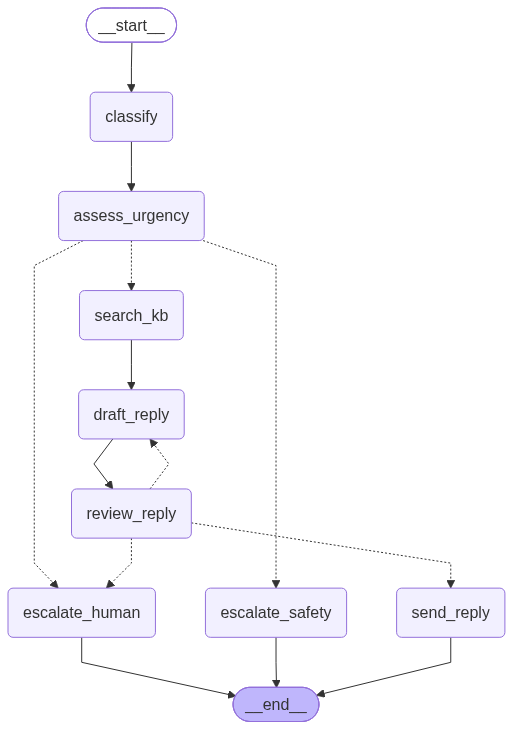

In [13]:
MAX_DRAFTS = 2


def after_urgency(t: Ticket) -> Literal["escalate_safety", "escalate_human", "search_kb"]:
    if t["safety_flag"]:
        return "escalate_safety"                       # no path around this
    if t["urgency"] >= 4 or t["intent"] == "account":
        return "escalate_human"                        # high stakes: a person handles it
    return "search_kb"


def after_review(t: Ticket) -> Literal["send_reply", "draft_reply", "escalate_human"]:
    if not t["review_feedback"]:
        return "send_reply"                            # approved
    if t["attempts"] >= MAX_DRAFTS:
        return "escalate_human"                        # two rejections: stop trying
    return "draft_reply"                               # try again with the feedback


b = StateGraph(Ticket)
for name, fn in [("classify", classify), ("assess_urgency", assess_urgency), ("search_kb", search_kb),
                 ("draft_reply", draft_reply), ("review_reply", review_reply),
                 ("escalate_safety", escalate_safety), ("escalate_human", escalate_human), ("send_reply", send_reply)]:
    b.add_node(name, fn)

b.add_edge(START, "classify")
b.add_edge("classify", "assess_urgency")
b.add_conditional_edges("assess_urgency", after_urgency)
b.add_edge("search_kb", "draft_reply")
b.add_edge("draft_reply", "review_reply")
b.add_conditional_edges("review_reply", after_review)
for terminal in ("escalate_safety", "escalate_human", "send_reply"):
    b.add_edge(terminal, END)

router = b.compile(checkpointer=InMemorySaver())
draw(router)

Read the picture as a policy document. Every ticket passes `classify` and `assess_urgency`.
Only three places can end a ticket, and a reply can't reach `send_reply` without going
through `review_reply`. The loop back to `draft_reply` is bounded by `MAX_DRAFTS`.

## Run the inbox

In [14]:
INBOX = [
    ("T-3001", "standard", "My Orbit got really hot while charging last night and there was a burning smell. Is it safe?"),
    ("T-3002", "standard", "Left earbud of my Pulse X1 keeps disconnecting on calls. Anything I can try?"),
    ("T-3003", "premium",  "I was charged twice for my Echo Bar order N104455. Please fix this today."),
    ("T-3004", "standard", "How long does delivery take to Guwahati?"),
    ("T-3005", "standard", "My Echo Bar stopped working after I dropped it in the pool. Is that covered?"),
    ("T-3006", "standard", "The Orbit app logs me out every day and I lose my workouts. So annoying."),
    ("T-3007", "standard", "I can't log in to my Nimbus account and the reset email never arrives."),
    ("T-3008", "standard", "I want to return my Pulse X1, delivered 3 days ago. Do I have to pay for the courier?"),
]

results = []
for tid, tier, text in INBOX:
    final = router.invoke({"ticket_id": tid, "text": text, "customer_tier": tier, "path": []},
                          {"configurable": {"thread_id": tid}})
    results.append({"ticket": tid, "intent": final.get("intent"), "product": final.get("product"),
                    "urgency": final.get("urgency"), "drafts": final.get("attempts", 0),
                    "outcome": final["outcome"], "path": " → ".join(final["path"])})

pd.set_option("display.max_colwidth", 80)
table = pd.DataFrame(results)
print(table[["ticket", "intent", "product", "urgency", "drafts", "outcome"]].to_string(index=False))

ticket    intent  product  urgency  drafts                                  outcome
T-3001    safety    Orbit        5       0 ESCALATED to product safety (4-hour SLA)
T-3002 technical Pulse X1        3       1                               REPLY SENT
T-3003   billing Echo Bar        4       0   ESCALATED to a human agent (urgency 4)
T-3004  shipping  unknown        2       1                               REPLY SENT
T-3005 technical Echo Bar        5       0   ESCALATED to a human agent (urgency 5)
T-3006 technical    Orbit        3       1                               REPLY SENT
T-3007   account  unknown        4       0   ESCALATED to a human agent (urgency 4)
T-3008   returns Pulse X1        3       1                               REPLY SENT


In [15]:
print(table[["ticket", "path"]].to_string(index=False))

ticket                                                                            path
T-3001                                     classify → assess_urgency → escalate_safety
T-3002 classify → assess_urgency → search_kb → draft_reply → review_reply → send_reply
T-3003                                      classify → assess_urgency → escalate_human
T-3004 classify → assess_urgency → search_kb → draft_reply → review_reply → send_reply
T-3005                                      classify → assess_urgency → escalate_human
T-3006 classify → assess_urgency → search_kb → draft_reply → review_reply → send_reply
T-3007                                      classify → assess_urgency → escalate_human
T-3008 classify → assess_urgency → search_kb → draft_reply → review_reply → send_reply


Look at the `drafts` column. If every reply passed review on its first draft, the
`review_reply → draft_reply` loop never ran — the loop is there for the day a draft is wrong.
Exercise 3 makes the reviewer stricter so you can watch it fire.

The `path` column is each ticket's journey through the graph — and it's something no
`create_agent` run gives you this cleanly. You can assert on it in tests: *"every ticket that
mentions burning ends in `escalate_safety`"* is now a one-line check.

In [16]:
# Policy tests -- the kind of assertion a graph makes easy.
for r in results:
    text = dict((t[0], t[2]) for t in INBOX)[r["ticket"]]
    if SAFETY_WORDS.search(text):
        assert r["outcome"].startswith("ESCALATED to product safety"), r
    if r["outcome"] == "REPLY SENT":
        assert "review_reply" in r["path"], r
print("policy tests passed: every safety ticket escalated, every sent reply was reviewed")

policy tests passed: every safety ticket escalated, every sent reply was reviewed


In [17]:
# Read the replies that went out.
for r in results:
    if r["outcome"] == "REPLY SENT":
        state = router.get_state({"configurable": {"thread_id": r["ticket"]}}).values
        print(f"--- {r['ticket']} ({r['drafts']} draft(s)) ---\n{state['draft']}\n")

--- T-3002 (1 draft(s)) ---
Hi there, thanks for reaching out! For your Pulse X1, try re-pairing the earbuds by placing both in the case, holding the case button for 10 seconds, then pairing again. Also, make sure your earbuds have the latest firmware, as version 1.5 addresses left bud disconnection during calls. If you need help updating, feel free to ask. We're here to support you!  
Warmly,  
Nimbus Support

--- T-3004 (1 draft(s)) ---
Hello! Delivery to Guwahati typically takes 7-10 days. If you have any other questions or need assistance, feel free to reach out. We're here to help!  

Warm regards,  
Nimbus Support

--- T-3006 (1 draft(s)) ---
Hi there, we're sorry to hear about the app logout issue and lost workouts. The good news is that the latest Orbit firmware 2.3.1 fixes the app logout bug and improves workout sync. This update installs automatically, but you can also update manually via the app under Settings > Firmware. We hope this helps improve your experience! If you ne

## Time travel on a real ticket: "what if they were premium?"

T-3002 (the disconnecting earbud) got a reply. Rewind it to just after classification,
change one fact — make it an angry premium customer on their third attempt — and let the
graph re-decide from there.

In [18]:
cfg = {"configurable": {"thread_id": "T-3002"}}
original = router.get_state(cfg).values
print("original :", original["outcome"], "| urgency", original["urgency"])

# find the checkpoint right after `classify` ran (the next node to run is assess_urgency)
after_classify = next(s for s in router.get_state_history(cfg) if s.next == ("assess_urgency",))
fork = router.update_state(after_classify.config,
                           {"customer_tier": "premium",
                            "text": original["text"] + " This is the third time — I'm a premium customer and need this fixed NOW."})
branched = router.invoke(None, fork)
print("what-if  :", branched["outcome"], "| urgency", branched["urgency"], "|", branched["urgency_reason"])

original : REPLY SENT | urgency 3


what-if  : ESCALATED to a human agent (urgency 4) | urgency 4 | The left earbud disconnecting during calls significantly impacts the user's experience, especially as a premium customer who needs reliable performance. While not a safety issue, it is urgent to resolve to maintain customer satisfaction.


Same ticket, rewound to one step, one fact changed — and the graph took a different path.
That's how you test a routing policy ("does an angry premium customer get a human?") without
re-running the whole pipeline, and how you debug a bad routing decision in production:
rewind to the checkpoint, change the input, watch the path.

---
# What you take forward

- **State** is a typed dict; nodes return **partial updates**; **reducers** decide how updates merge.
- **Conditional edges** are routers; a **back-edge** is a loop — and every loop needs a budget.
- `create_agent` is `agent → tools → agent`: you can now build it, and change it.
- **Checkpoints** give memory, history and **time travel**.
- **Draw the graph when the order is policy.** Let the model choose only where a choice is safe.

**Next session:** a graph that writes code, runs the tests, and fixes its own bugs — and
stops to ask a human before it does anything risky.

---
## Exercises

**1. A spam lane.** Add an intent `"spam"` that ends immediately with outcome `"IGNORED"`.
Where does the edge go?

**2. Break the reducer.** Remove `operator.add` from `path` and rerun. What happens to the
journey column — and why?

**3. A stricter reviewer.** Make the reviewer reject anything over 60 words. How many tickets
now hit `MAX_DRAFTS` and escalate?

**4. Parallel checks.** Run `assess_urgency` and `search_kb` *in parallel* after `classify`
(two edges out of one node). What has to change in `after_urgency`?

**5. Time travel for debugging.** Pick the ticket with the most drafts. Rewind to its first
`review_reply`, read the feedback, and edit the draft by hand with `update_state`. Does the
reviewer approve your version?